# 03. Metrics, probability distributions and thresholds (v2)
Why do the models predict almost no positive cases at the 0.5 threshold, and what happens at thresholds chosen on **validation** data? The test set is only used to report results.

In [ ]:
import os, sys, json, gc, time, warnings, subprocess
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
ROOT = os.environ.get("PA_ROOT", "/content/drive/MyDrive/privacy-audit/")
sys.path.insert(0, ROOT)          # pa_lib.py must sit in the privacy-audit folder on Drive
def pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
from pa_lib import *
make_dirs()
print(versions())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'python': '3.13.18', 'numpy': '2.1.3', 'pandas': '2.2.3', 'torch': '2.11.0+cpu', 'opacus': None, 'art': None, 'sklearn': '1.6.1'}


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve
Xtr, ytr = load_split("target_train"); Xva, yva = load_split("target_val"); Xte, yte = load_split("target_test")
input_dim = Xtr.shape[1]
prevalence = float(ytr.mean())
NAMES = model_names()
print(f"readmitted share: train {ytr.mean():.3f} | validation {yva.mean():.3f} | test {yte.mean():.3f}")

P = {}
for name in NAMES:
    for s in SEEDS:
        m = load_model(name, s, input_dim)
        P[(name, s)] = (proba(m, Xva)[:, 1], proba(m, Xte)[:, 1])
np.savez_compressed(RESULTS + "predictions.npz", **{f"{n}__{s}__{part}": a for (n, s), t in P.items() for part, a in zip(("val", "test"), t)})
print("predictions saved for", len(P), "models")


readmitted share: train 0.112 | validation 0.119 | test 0.111
predictions saved for 40 models


                 mean    p05  median    p95    max  share_over_0.5  mean_if_readmitted  mean_if_not
model                                                                                              
baseline_e50    0.109  0.000   0.002  0.823  1.000           0.091               0.167        0.101
baseline_early  0.117  0.050   0.104  0.231  0.499           0.001               0.155        0.112
dpsgd_eps0.5    0.014  0.007   0.013  0.028  0.074           0.000               0.017        0.014
dpsgd_eps1      0.014  0.006   0.012  0.029  0.106           0.000               0.019        0.014
dpsgd_eps2      0.014  0.006   0.012  0.030  0.134           0.000               0.020        0.014
dpsgd_eps5      0.014  0.006   0.011  0.029  0.154           0.000               0.020        0.013
dpsgd_eps10     0.014  0.006   0.011  0.030  0.160           0.000               0.020        0.013
dpsgd_eps100    0.014  0.005   0.010  0.031  0.177           0.000               0.021        0.013


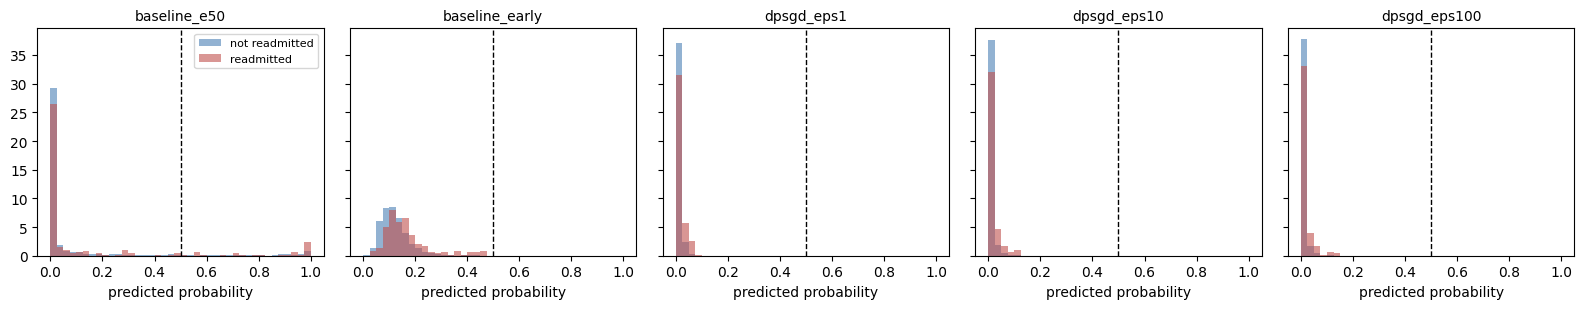

In [ ]:
# 1. WHY no positives at 0.5? Look at what the models actually output (validation data).
rows = []
for (name, s), (pv, pt) in P.items():
    d = prob_summary(pv, yva); d.update(model=name); rows.append(d)
ps = pd.DataFrame(rows).groupby("model").mean(numeric_only=True).reindex(NAMES).round(3)
ps.to_csv(RESULTS + "prob_summary.csv")
print(ps.to_string())
print(f"\nBase rate of readmission: {prevalence:.3f}")
print("If the 95th percentile (p95) and max are below 0.5, no patient can ever reach the 0.5 cut-off.")

import matplotlib.pyplot as plt
show = ["baseline_e50", "baseline_early", "dpsgd_eps1", "dpsgd_eps10", "dpsgd_eps100"]
fig, ax = plt.subplots(1, len(show), figsize=(16, 3.2), sharey=True)
for a, name in zip(ax, show):
    pv = P[(name, 1)][0]
    a.hist(pv[yva == 0], bins=40, range=(0, 1), alpha=.6, density=True, label="not readmitted", color="#4a7fb5")
    a.hist(pv[yva == 1], bins=40, range=(0, 1), alpha=.6, density=True, label="readmitted", color="#c0504d")
    a.axvline(0.5, color="k", ls="--", lw=1); a.set_title(name, fontsize=10); a.set_xlabel("predicted probability")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIGS + "probability_histograms.png", dpi=150); plt.show()


In [ ]:
# 2. Threshold-free metrics: ROC-AUC, PR-AUC, Brier score, calibration (validation and test)
rows = []
for (name, s), (pv, pt) in P.items():
    for part, p, y in (("validation", pv, yva), ("test", pt, yte)):
        b = brier_score_loss(y, p); ref = float(np.mean((y - prevalence) ** 2))
        rows.append({"model": name, "seed": s, "set": part, "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
                     "brier": b, "brier_skill": 1 - b / ref, "ece": ece(y, p), "accuracy_at_0.5": float(((p >= .5) == y).mean())})
mm = pd.DataFrame(rows); mm.to_csv(RESULTS + "model_metrics.csv", index=False)
t = mm[mm["set"] == "test"].groupby("model")[["roc_auc", "pr_auc", "brier", "brier_skill", "ece", "accuracy_at_0.5"]].agg(["mean", "std"]).reindex(NAMES).round(3)
print("TEST SET, mean and spread over 5 seeds")
print(t.to_string())
print(f"\nReference values: PR-AUC of a model with no skill = the base rate = {yte.mean():.3f}; Brier skill 0 = no better than always predicting the base rate (negative = worse).")


TEST SET, mean and spread over 5 seeds
               roc_auc        pr_auc         brier        brier_skill           ece        accuracy_at_0.5       
                  mean    std   mean    std   mean    std        mean    std   mean    std            mean    std
model                                                                                                            
baseline_e50     0.542  0.028  0.129  0.010  0.148  0.008      -0.502  0.079  0.148  0.010           0.830  0.009
baseline_early   0.609  0.003  0.165  0.002  0.097  0.000       0.014  0.001  0.011  0.002           0.889  0.000
dpsgd_eps0.5     0.567  0.008  0.142  0.005  0.107  0.000      -0.092  0.002  0.097  0.001           0.889  0.000
dpsgd_eps1       0.582  0.007  0.148  0.006  0.107  0.000      -0.092  0.002  0.097  0.001           0.889  0.000
dpsgd_eps2       0.592  0.005  0.152  0.005  0.107  0.000      -0.092  0.002  0.097  0.001           0.889  0.000
dpsgd_eps5       0.600  0.003  0.155  0.003  0.10

In [ ]:
# 3. Thresholds chosen on VALIDATION data only, then reported on the test set
rows = []
for (name, s), (pv, pt) in P.items():
    for rule, th in pick_thresholds(yva, pv).items():
        r = confusion_at(yte, pt, th); r.update(model=name, seed=s, rule=rule); rows.append(r)
for rule, th in (("trivial: predict everyone negative", 1.0), ("trivial: predict everyone positive", 0.0)):
    r = confusion_at(yte, np.zeros(len(yte)), th); r.update(model="no model", seed=0, rule=rule); rows.append(r)
tr_df = pd.DataFrame(rows); tr_df.to_csv(RESULTS + "threshold_results.csv", index=False)
tr_df["lift"] = tr_df["precision"] / float(yte.mean())

print(f"TEST RESULTS, mean over seeds. Test base rate = {yte.mean():.3f}; 'predict everyone positive' gives F1 = {2*yte.mean()/(1+yte.mean()):.3f}")
for rule in ["default 0.5", "best F1 (validation)", "Youden (validation)", "flag top 20% (validation)"]:
    s = tr_df[tr_df["rule"] == rule].groupby("model")[["threshold", "precision", "recall", "f1", "flagged", "lift"]].mean().reindex(NAMES).round(3)
    print(f"\n--- threshold rule: {rule} ---"); print(s.to_string())
print("\n--- trivial references ---")
print(tr_df[tr_df["model"] == "no model"][["rule", "precision", "recall", "f1", "flagged"]].round(3).to_string(index=False))
summary_thr = tr_df[tr_df["model"] != "no model"].groupby(["rule", "model"])[["threshold", "precision", "recall", "f1", "flagged", "lift"]].agg(["mean", "std"]).round(3)
summary_thr.to_csv(RESULTS + "threshold_summary.csv")


TEST RESULTS, mean over seeds. Test base rate = 0.111; 'predict everyone positive' gives F1 = 0.199

--- threshold rule: default 0.5 ---
                threshold  precision  recall    f1  flagged   lift
model                                                             
baseline_e50          0.5       0.15   0.116  0.13    0.085  1.355
baseline_early        0.5       0.00   0.000  0.00    0.000  0.000
dpsgd_eps0.5          0.5       0.00   0.000  0.00    0.000  0.000
dpsgd_eps1            0.5       0.00   0.000  0.00    0.000  0.000
dpsgd_eps2            0.5       0.00   0.000  0.00    0.000  0.000
dpsgd_eps5            0.5       0.00   0.000  0.00    0.000  0.000
dpsgd_eps10           0.5       0.00   0.000  0.00    0.000  0.000
dpsgd_eps100          0.5       0.00   0.000  0.00    0.000  0.000

--- threshold rule: best F1 (validation) ---
                threshold  precision  recall     f1  flagged   lift
model                                                              
baseline_e5

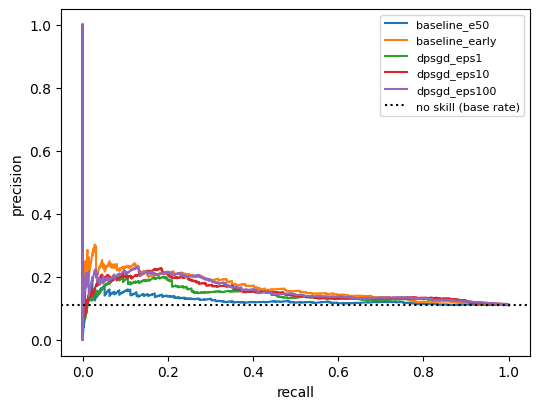

In [ ]:
# 4. Precision-recall curves on the test set (seed 1) with the no-skill line
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for name in show:
    pr, rc, _ = precision_recall_curve(yte, P[(name, 1)][1]); ax.plot(rc, pr, label=name)
ax.axhline(yte.mean(), color="k", ls=":", label="no skill (base rate)")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(FIGS + "pr_curves_test.png", dpi=150); plt.show()


In [ ]:
# 5. Keep the earlier (v1) numbers for comparison. The v1 files are never changed.
V1_DATA, V1_MODELS = ROOT + "data/", ROOT + "models/final/"
if os.path.exists(V1_DATA + "target_test.csv") and os.path.isdir(V1_MODELS):
    d1 = pd.read_csv(V1_DATA + "target_test.csv")
    X1 = np.ascontiguousarray(d1.drop(columns=["outcome"]).astype(np.float32).values); y1 = d1["outcome"].values.astype(np.int64)
    rows = []
    for name in ["baseline_e50", "baseline_early_e4"] + [f"dpsgd_eps{e}" for e in EPSILONS]:
        for s in SEEDS:
            path = f"{V1_MODELS}{name}_seed{s}.pt"
            if not os.path.exists(path):
                continue
            m = Net(X1.shape[1]); m.load_state_dict(torch.load(path, map_location="cpu")); m.eval()
            p = proba(m, X1)[:, 1]
            rows.append({"version": "v1 (visit-level split, test overlap 39%)", "model": name, "seed": s,
                         "roc_auc": roc_auc_score(y1, p), "pr_auc": average_precision_score(y1, p), "brier": brier_score_loss(y1, p)})
    v1 = pd.DataFrame(rows); v1.to_csv(RESULTS + "v1_metrics_preserved.csv", index=False)
    v1m = v1.groupby("model")[["roc_auc", "pr_auc"]].mean().rename(index={"baseline_early_e4": "baseline_early"})
    v2m = mm[mm["set"] == "test"].groupby("model")[["roc_auc", "pr_auc"]].mean()
    cmp_ = v1m.join(v2m, lsuffix=" (v1)", rsuffix=" (v2)").reindex(NAMES).round(3)
    cmp_.to_csv(RESULTS + "v1_vs_v2_comparison.csv"); print(cmp_.to_string())
else:
    print("v1 files not found, nothing to compare")


                roc_auc (v1)  pr_auc (v1)  roc_auc (v2)  pr_auc (v2)
model                                                               
baseline_e50           0.562        0.148         0.542        0.129
baseline_early         0.636        0.213         0.609        0.165
dpsgd_eps0.5           0.617        0.203         0.567        0.142
dpsgd_eps1             0.624        0.210         0.582        0.148
dpsgd_eps2             0.629        0.212         0.592        0.152
dpsgd_eps5             0.632        0.212         0.600        0.155
dpsgd_eps10            0.632        0.211         0.604        0.157
dpsgd_eps100           0.627        0.207         0.609        0.161


In [ ]:
from sklearn.linear_model import LogisticRegression
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

rows = []
for (name, s), (pv, pt) in P.items():
    cal = LogisticRegression(C=1e6).fit(logit(pv), yva)        # fitted on validation only
    pc = cal.predict_proba(logit(pt))[:, 1]
    rows.append({"model": name, "seed": s, "brier_before": brier_score_loss(yte, pt), "brier_after": brier_score_loss(yte, pc),
                 "ece_before": ece(yte, pt), "ece_after": ece(yte, pc), "roc_auc": roc_auc_score(yte, pc)})
c = pd.DataFrame(rows).groupby("model").mean(numeric_only=True).drop(columns="seed").reindex(NAMES).round(3)
c.to_csv(RESULTS + "calibration_after_adjustment.csv")
print(c.to_string())

                brier_before  brier_after  ece_before  ece_after  roc_auc
model                                                                    
baseline_e50           0.148        0.098       0.148      0.011    0.542
baseline_early         0.097        0.097       0.011      0.012    0.609
dpsgd_eps0.5           0.107        0.098       0.097      0.014    0.567
dpsgd_eps1             0.107        0.098       0.097      0.013    0.582
dpsgd_eps2             0.107        0.098       0.097      0.010    0.592
dpsgd_eps5             0.107        0.098       0.098      0.008    0.600
dpsgd_eps10            0.107        0.097       0.098      0.009    0.604
dpsgd_eps100           0.107        0.097       0.098      0.010    0.609
